# LAB 07 — Bài 12: Transformer Architecture

Notebook triển khai Transformer Encoder cơ bản cho phân loại cảm xúc IMDb: sinusoidal positional encoding, self-attention nhiều head tự cài, residual + LayerNorm, FFN, huấn luyện và đánh giá.



## 1. Imports và seed

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 7
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

def positional_encoding(max_length, d_model):
    """Sinusoidal positional encoding, returned as [1, T, D]."""
    if max_length <= 0 or d_model <= 0:
        raise ValueError("max_length and d_model must be positive")
    pos = np.arange(max_length, dtype=np.float32)[:, None]
    dim = np.arange(d_model, dtype=np.float32)[None, :]
    rate = np.power(10000.0, -(2 * np.floor(dim / 2)) / d_model)
    angle = pos * rate
    values = np.where((dim.astype(int) % 2) == 0, np.sin(angle), np.cos(angle))
    return tf.constant(values[None, :, :], dtype=tf.float32)

class MultiHeadSelfAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        if d_model % n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.d_model, self.n_heads = d_model, n_heads
        self.d_k = d_model // n_heads
        self.q_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.k_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.v_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.o_proj = tf.keras.layers.Dense(d_model)
        self.drop = tf.keras.layers.Dropout(dropout)

    def split_heads(self, x):
        b, t = tf.shape(x)[0], tf.shape(x)[1]
        x = tf.reshape(x, [b, t, self.n_heads, self.d_k])
        return tf.transpose(x, [0, 2, 1, 3])

    def call(self, x, training=False, key_mask=None):
        q, k, v = [self.split_heads(layer(x)) for layer in (self.q_proj, self.k_proj, self.v_proj)]
        scores = tf.matmul(q, k, transpose_b=True) / tf.math.sqrt(tf.cast(self.d_k, x.dtype))
        if key_mask is not None:
            mask = tf.cast(key_mask[:, None, None, :], tf.bool)
            scores = tf.where(mask, scores, tf.cast(-1e9, scores.dtype))
        weights = tf.nn.softmax(scores, axis=-1)
        context = tf.matmul(self.drop(weights, training=training), v)
        context = tf.transpose(context, [0, 2, 1, 3])
        shape = tf.shape(context)
        context = tf.reshape(context, [shape[0], shape[1], self.d_model])
        return self.o_proj(context), weights

class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(d_ff, activation="relu"),
            tf.keras.layers.Dense(d_model),
        ])
        self.drop1 = tf.keras.layers.Dropout(dropout)
        self.drop2 = tf.keras.layers.Dropout(dropout)
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

    def call(self, x, training=False, key_mask=None, return_attention=False):
        attn, weights = self.attention(x, training=training, key_mask=key_mask)
        x = self.norm1(x + self.drop1(attn, training=training))
        y = self.ffn(x, training=training)
        y = self.norm2(x + self.drop2(y, training=training))
        return (y, weights) if return_attention else y

# Shape sanity check: B=8, T=100, d_model=128, heads=4
sample = tf.random.normal([8, 100, 128], seed=SEED)
block = TransformerBlock(128, 4, 256)
out, weights = block(sample, return_attention=True)
print("input:", sample.shape, "attention weights:", weights.shape, "output:", out.shape)
assert tuple(out.shape) == (8, 100, 128)
assert tuple(weights.shape) == (8, 4, 100, 100)

TensorFlow: 2.21.0
GPU: []
input: (8, 100, 128) attention weights: (8, 4, 100, 100) output: (8, 100, 128)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
train / validation / test: (22500, 128) (2500, 128) (25000, 128)


Model: "transformer_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (2, 128, 64)           │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ ?                      │        33,280 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (2, 1)                 │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,345 (5.01 MB)

 Trainable params: 1,313,345 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 103s 275ms/step - accuracy: 0.8009 - loss: 0.4141 - val_accuracy: 0.8588 - val_loss: 0.3387
Epoch 2/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 95s 270ms/step - accuracy: 0.9156 - loss: 0.2134 - val_accuracy: 0.8400 - val_loss: 0.4741
Epoch 3/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 142s 270ms/step - accuracy: 0.9576 - loss: 0.1143 - val_accuracy: 0.8376 - val_loss: 0.5167
Training seconds: 339.5
Accuracy: 0.8006 F1: 0.8032
              precision    recall  f1-score   support

    negative       0.81      0.79      0.80     12500
    positive       0.79      0.81      0.80     12500

    accuracy                           0.80     25000
   macro avg       0.80      0.80      0.80     25000
weighted avg       0.80      0.80      0.80     25000



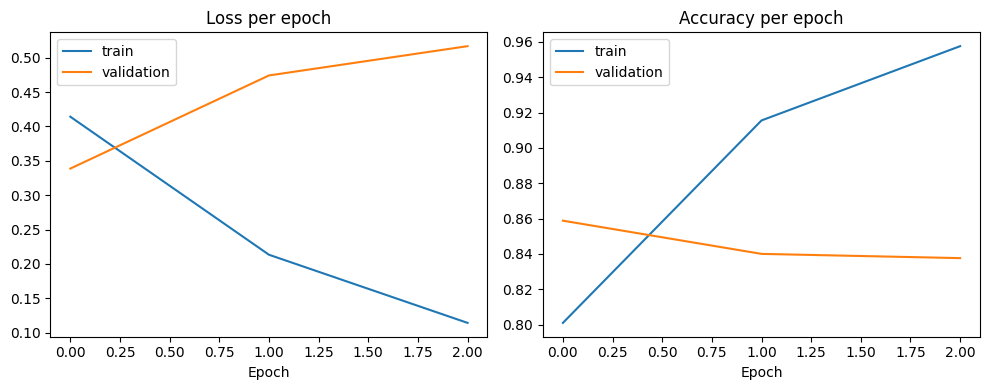

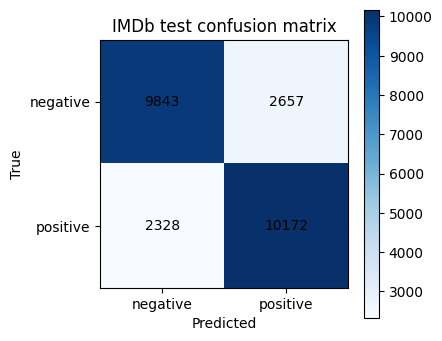

In [ ]:
# IMDb sentiment classification (binary)
MAX_WORDS, MAX_LEN = 20000, 128
BATCH_SIZE, EMBED_DIM, D_FF, EPOCHS = 64, 64, 128, 3
(x_train_raw, y_train_all), (x_test_raw, y_test) = imdb.load_data(num_words=MAX_WORDS, seed=SEED)
x_train_all = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="post", truncating="post").astype("int32")
x_test = pad_sequences(x_test_raw, maxlen=MAX_LEN, padding="post", truncating="post").astype("int32")
y_train_all, y_test = np.asarray(y_train_all), np.asarray(y_test)
train_idx, val_idx = train_test_split(np.arange(len(y_train_all)), test_size=0.1, random_state=SEED, stratify=y_train_all)
x_train, y_train = x_train_all[train_idx], y_train_all[train_idx]
x_val, y_val = x_train_all[val_idx], y_train_all[val_idx]
print("train / validation / test:", x_train.shape, x_val.shape, x_test.shape)

class TransformerClassifier(tf.keras.Model):
    def __init__(self, vocab_size, max_length, d_model=64, n_heads=4, d_ff=128, dropout=0.1):
        super().__init__()
        self.embedding = tf.keras.layers.Embedding(vocab_size, d_model, mask_zero=True)
        self.scale = tf.math.sqrt(tf.cast(d_model, tf.float32))
        self.position = positional_encoding(max_length, d_model)
        self.encoder = TransformerBlock(d_model, n_heads, d_ff, dropout)
        self.pool = tf.keras.layers.GlobalAveragePooling1D()
        self.classifier = tf.keras.layers.Dense(1, activation="sigmoid")

    def call(self, token_ids, training=False):
        mask = tf.not_equal(token_ids, 0)
        x = self.embedding(token_ids) * self.scale
        x = x + self.position[:, :tf.shape(x)[1], :]
        x = self.encoder(x, training=training, key_mask=mask)
        x = self.pool(x, mask=mask)
        return self.classifier(x)

model = TransformerClassifier(MAX_WORDS, MAX_LEN, EMBED_DIM, 4, D_FF)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
_ = model(tf.zeros([2, MAX_LEN], dtype=tf.int32))
model.summary()
start = time.perf_counter()
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
training_seconds = time.perf_counter() - start
prob = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0).ravel()
pred = (prob >= 0.5).astype("int32")
print("Training seconds:", round(training_seconds, 1))
print("Accuracy:", round(accuracy_score(y_test, pred), 4), "F1:", round(f1_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["negative", "positive"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["loss"], label="train"); axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set(title="Loss per epoch", xlabel="Epoch"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train"); axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set(title="Accuracy per epoch", xlabel="Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4, 4)); plt.imshow(cm, cmap="Blues"); plt.title("IMDb test confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.xticks([0,1], ["negative","positive"]); plt.yticks([0,1], ["negative","positive"])
for (i, j), value in np.ndenumerate(cm): plt.text(j, i, str(value), ha="center", va="center")
plt.colorbar(); plt.show()

Example index: 0 true label: 0 predicted: 0 probability: 0.0017


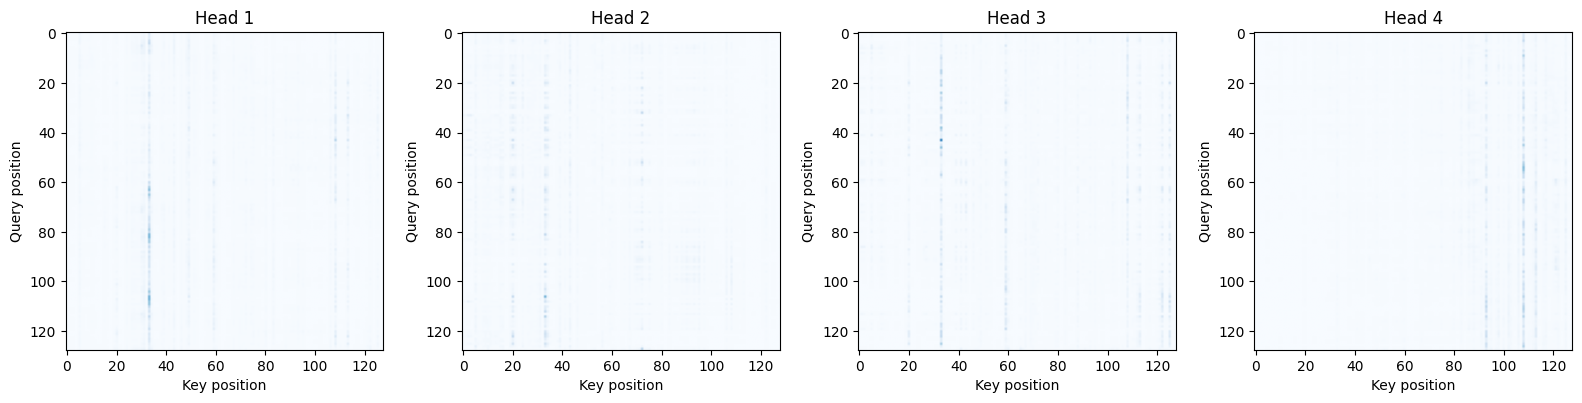

,max_length,attention_elements_per_head,ratio_vs_32
0,32,1024,1.0
1,64,4096,4.0
2,128,16384,16.0
3,256,65536,64.0


In [ ]:
# Attention-head diversity: inspect one correctly/incorrectly classified review
example_index = int(np.flatnonzero(pred == y_test)[0]) if np.any(pred == y_test) else 0
ids = x_test[example_index:example_index + 1]
valid = int(np.sum(ids[0] != 0))
x = model.embedding(ids) * model.scale
x = x + model.position[:, :tf.shape(x)[1], :]
_, attn = model.encoder(x, training=False, key_mask=tf.not_equal(ids, 0), return_attention=True)
attn = attn[0, :, :valid, :valid].numpy()
print("Example index:", example_index, "true label:", int(y_test[example_index]), "predicted:", int(pred[example_index]), "probability:", round(float(prob[example_index]), 4))
_, axes = plt.subplots(1, attn.shape[0], figsize=(4 * attn.shape[0], 4), squeeze=False)
for h, ax in enumerate(axes[0]):
    im = ax.imshow(attn[h], cmap="Blues", vmin=0, vmax=1)
    ax.set(title=f"Head {h + 1}", xlabel="Key position", ylabel="Query position")
plt.tight_layout(); plt.show()

# Self-attention cost grows quadratically with sequence length.
lengths = [32, 64, 128, 256]
cost_table = pd.DataFrame({"max_length": lengths, "attention_elements_per_head": [t*t for t in lengths], "ratio_vs_32": [(t/32)**2 for t in lengths]})
display(cost_table)

# Optional comparable recurrent baseline. Set True to run another full training job.
RUN_LSTM_BASELINE = False
if RUN_LSTM_BASELINE:
    lstm = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN,), dtype="int32"),
        tf.keras.layers.Embedding(MAX_WORDS, EMBED_DIM, mask_zero=True),
        tf.keras.layers.LSTM(EMBED_DIM),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    lstm.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    t0 = time.perf_counter()
    lstm.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
    lstm_seconds = time.perf_counter() - t0
    lstm_pred = (lstm.predict(x_test, batch_size=BATCH_SIZE, verbose=0).ravel() >= 0.5).astype("int32")
    print({"model": "LSTM", "parameters": lstm.count_params(), "seconds": round(lstm_seconds, 1),
           "accuracy": accuracy_score(y_test, lstm_pred), "f1": f1_score(y_test, lstm_pred)})

# Reflection: compare measured accuracy/F1 and training time; analyze at least 3 errors.
# Discuss positional information, head count, padding masks, truncation, negation, and ambiguity.